# 6장 스트림 기반 선택적 샘플링

샘플이 하나씩 도착하고 다시 오지 않는 스트림 시나리오를 다룬다. 도착한 샘플마다 라벨을 요청할지 바로 정해야 하므로 풀 기반의 「상위 k개」 대신 임계값으로 판단한다.

- 6.1 스트림 시나리오의 정의
- 6.2 고정 임계값 질의
- 6.3 적응형 임계값과 예산 제약
- 6.4 질의율과 성능의 절충
- 6.5 개념 표류 상황의 스트림 질의
- 6.6 풀 기반 루프와의 비교

CPU만으로 돈다. 1장이 만든 `data/` 의 분할 파일을 읽고 3장 결과 파일 `results/ch03_*.csv` 를 6.6절 비교에 쓴다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


3장의 엔트로피 점수와 점수 기반 질의 함수도 다시 싣는다. 스트림의 임계값은 클래스 수가 다른 두 데이터에 같은 눈금을 쓰려고 엔트로피를 log C로 나눈 정규화 엔트로피에 건다.

In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

def norm_entropy(P):
    # 0이면 확신, 1이면 모든 클래스에 같은 확률
    return score_entropy(P) / np.log(P.shape[1])

## 6.1 스트림 시나리오의 정의

시드마다 풀 20,000개를 섞어 도착 순서를 정한다. 처음 100개는 조건 없이 라벨을 받아 초기 모델을 만들고 나머지 19,900개가 차례로 도착한다. 도착 순서를 200개 덩어리로 끊어 덩어리 안에서는 같은 모델이 샘플마다 차례로 결정하고 덩어리가 끝나면 새 라벨로 재학습한다. 덩어리 단위 재학습은 계산 비용 때문에 둔 근사이고 6.3절에서 덩어리 크기의 영향을 따로 잰다.

질의 함수는 2장 시그니처를 그대로 쓴다. `idx_u` 자리에 도착한 덩어리만 넘기고 `k` 는 남은 예산으로 쓴다. 질의 함수는 0개부터 k개까지 고른다. 라벨을 받기 전에 도착 샘플을 먼저 예측해 두는 사전 순차 평가(prequential evaluation)도 함께 기록한다. 예산을 다 쓴 뒤에도 스트림은 끝까지 흘려보내며 마지막 모델로 계속 예측한다.

In [3]:
# ── 스트림 루프 ────
CHUNK = 200

def run_stream(query_fn, oracle_fn, data, seed, order=None, n_init=N_INIT, budget=BUDGET, chunk=CHUNK):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    order = rng.permutation(n) if order is None else order
    idx_l = order[:n_init]
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    log, preq, n_fit = [], [], -1
    for start in list(range(n_init, len(order), chunk)) + [len(order)]:
        if len(idx_l) != n_fit:                                                    # 새 라벨이 있을 때만
            model, n_fit = train_model(data["X_pool"][idx_l], y_l, seed), len(idx_l)  # 1. train
            y_hat = model.predict(data["X_test"])
        log.append(dict(seed=seed, n_seen=start, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if start == len(order):
            break
        arrive = order[start:start + chunk]
        preq.append(model.predict(data["X_pool"][arrive]))                          # 라벨을 보기 전에 먼저 예측한다
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, arrive, budget - len(idx_l), rng)    # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                    # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                              # 5. update
    return pd.DataFrame(log), idx_l, np.concatenate(preq)

스트림 질의 함수는 임계값 상태를 가진다. 시드마다 상태가 새로 시작되도록 전략은 질의 함수를 만드는 함수(팩토리)로 넘긴다. 실험 도구도 스트림용으로 둔다. 라벨 축 ALC는 라벨 수 100~2,000을 50 간격 격자로 보간해 계산하고, 예산을 다 쓰지 못한 전략은 마지막 성능을 그대로 이어 붙인다. 도착 축 ALC는 도착 수 100~20,000 구간의 면적이다.

In [4]:
# ── 스트림 실험 도구 ────
GRID = np.arange(N_INIT, BUDGET + 1, K)
RATE = (BUDGET - N_INIT) / (20000 - N_INIT)          # 예산을 정확히 다 쓰는 평균 질의율

def run_stream_strategies(factories, data, seeds=SEEDS, n_jobs=-1, **kw):
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in factories for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_stream)(factories[name](), oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(factories)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _, _) in zip(jobs, out)], ignore_index=True)

def label_curve(d, metric="f1"):
    g = d.drop_duplicates("n_labeled", keep="last")
    return np.interp(GRID, g.n_labeled, g[metric])      # 격자 밖(예산 미사용)은 마지막 값을 잇는다

def summarize_stream(res, metric="f1"):
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        per = []
        for _, d in g.groupby("seed"):
            done = d[d.n_labeled >= BUDGET].n_seen
            u = (d.n_seen - d.n_seen.iloc[0]) / (d.n_seen.iloc[-1] - d.n_seen.iloc[0])
            per.append(dict(ALC_label=alc(GRID, label_curve(d, metric)),
                            ALC_seen=np.sum(np.diff(u) * (d[metric].values[1:] + d[metric].values[:-1]) / 2),
                            final=d[metric].iloc[-1], labels=d.n_labeled.iloc[-1],
                            exhaust=done.iloc[0] if len(done) else np.nan))
        p = pd.DataFrame(per)
        rows.append(dict(strategy=name, ALC_label=p.ALC_label.mean(), ALC_label_std=p.ALC_label.std(ddof=0),
                         ALC_seen=p.ALC_seen.mean(), final=p.final.mean(), labels=p.labels.mean(),
                         exhaust=p.exhaust.mean(), t_query=g.t_query.mean()))
    return pd.DataFrame(rows).round(4)

## 6.2 고정 임계값 질의

정규화 엔트로피가 τ를 넘으면 라벨을 요청한다. 남은 예산(k)을 넘지 않는 범위에서 도착 순서대로 받는다. 무작위 기준선은 평균 질의율 RATE(약 9.5%)로 동전을 던져 고른다.

In [5]:
# ── 스트림 질의 함수: 무작위와 고정 임계값 ────
def make_stream_random(rate=RATE):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        return idx_u[rng.random(len(idx_u)) < rate][:k]
    return query_fn

def make_fixed(tau):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        u = norm_entropy(proba(model, data["X_pool"][idx_u], data["n_classes"]))
        return idx_u[u > tau][:k]
    return query_fn

TAUS = [0.5, 0.7, 0.8, 0.9, 0.95]

## 6.3 적응형 임계값과 예산 제약

가변 불확실성(variable uncertainty, VU)은 질의할 때마다 임계값 θ를 (1 + s)배로 올리고 질의하지 않을 때마다 (1 − s)배로 내린다. 쉬운 샘플이 이어지면 θ가 내려가 질의를 다시 시작하고 어려운 샘플이 몰리면 θ가 올라가 예산을 아낀다. 지금까지의 질의율이 RATE를 넘으면 판단 자체를 건너뛰어 예산을 지킨다. 무작위 가변 불확실성(randomized VU, RVU)은 비교 기준을 θ·η(η ~ N(1, δ²))로 흔들어 확신하는 샘플도 가끔 질의한다. Žliobaitė 등(2014)의 규칙을 정규화 엔트로피 위에 옮겼다.

In [6]:
# ── 스트림 질의 함수: 가변 불확실성 ────
def make_vu(theta=0.5, s=0.01, rate=RATE, delta=0.0, trace=None):
    st = dict(theta=theta, seen=0, asked=0)
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        u = norm_entropy(proba(model, data["X_pool"][idx_u], data["n_classes"]))
        eta = rng.normal(1.0, delta, len(u)) if delta else np.ones(len(u))
        picked = []
        for i, ui, e in zip(idx_u, u, eta):
            st["seen"] += 1
            if st["asked"] < st["seen"] * rate and len(picked) < k:              # 예산 조건
                ask = ui > st["theta"] * e
                st["theta"] *= (1 + s) if ask else (1 - s)
                st["asked"] += ask
                picked += [i] if ask else []
            if trace is not None:
                trace.append((st["theta"], st["asked"] / st["seen"]))
        return np.array(picked, dtype=int)
    return query_fn

FACTORIES = {"Random": make_stream_random,
             **{f"고정 τ={t}": (lambda t=t: make_fixed(t)) for t in TAUS},
             "VU": make_vu,
             "RVU": lambda: make_vu(delta=1.0)}

In [7]:
# ── 스트림 전략 실험 ────
res = {name: run_stream_strategies(FACTORIES, d) for name, d in DATA.items()}
for name, r in res.items():
    r.to_csv(f"results/ch06_{name}.csv", index=False)
    print(f"\n{name} 매크로 F1")
    print(summarize_stream(r).to_string(index=False))

nsmc  Random, 고정 τ=0.5, 고정 τ=0.7, 고정 τ=0.8, 고정 τ=0.9, 고정 τ=0.95, VU, RVU 완료


ynat  Random, 고정 τ=0.5, 고정 τ=0.7, 고정 τ=0.8, 고정 τ=0.9, 고정 τ=0.95, VU, RVU 완료

nsmc 매크로 F1
 strategy  ALC_label  ALC_label_std  ALC_seen  final  labels  exhaust  t_query
   Random     0.7351         0.0148    0.7349 0.7801  1992.6  19900.0   0.0000
 고정 τ=0.5     0.7336         0.0066    0.7781 0.7829  2000.0   2300.0   0.0006
 고정 τ=0.7     0.7345         0.0063    0.7792 0.7842  2000.0   2500.0   0.0006
 고정 τ=0.8     0.7365         0.0054    0.7805 0.7859  2000.0   2860.0   0.0006
 고정 τ=0.9     0.7398         0.0030    0.7776 0.7833  2000.0   3540.0   0.0006
고정 τ=0.95     0.7431         0.0029    0.7794 0.7872  2000.0   4780.0   0.0006
       VU     0.7416         0.0081    0.7422 0.7841  2000.0  20000.0   0.0010
      RVU     0.7351         0.0082    0.7354 0.7814  2000.0  20000.0   0.0009

ynat 매크로 F1
 strategy  ALC_label  ALC_label_std  ALC_seen  final  labels  exhaust  t_query
   Random     0.5343         0.0113    0.5341 0.6434  1992.6  19900.0   0.0000
 고정 τ=0.5     0.5402         

6.2절의 고정 임계값 격자를 도착 수 축 학습 곡선으로 그린다. 낮은 τ는 초반에 예산을 다 쓰고 멈추며 높은 τ는 예산을 남긴다.

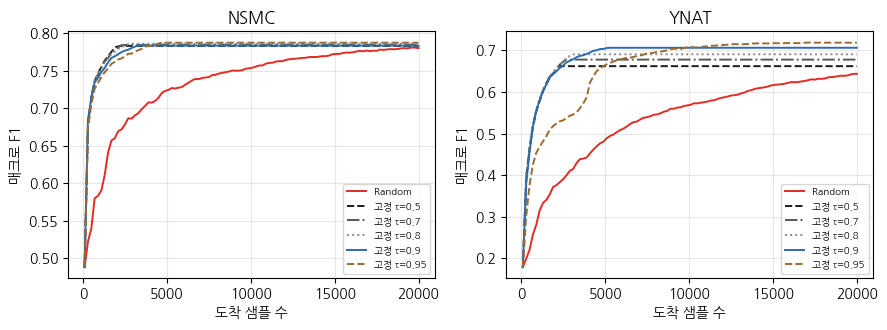

In [8]:
# ── 고정 임계값 격자 그림 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, res.items()):
    for (strat, g), (c, ls) in zip(r[r.strategy.str.startswith("고정") | (r.strategy == "Random")].groupby("strategy", sort=False), STYLES):
        m = g.groupby("n_seen").f1.mean()
        ax.plot(m.index, m.values, color=c, ls=ls, lw=1.4, label=strat)
    ax.set(title=name.upper(), xlabel="도착 샘플 수", ylabel="매크로 F1")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("out/ch06_threshold_grid.png", dpi=200)

VU와 RVU의 θ와 누적 질의율이 스트림을 따라 어떻게 움직이는지 시드 0에서 샘플 단위로 기록한다.

nsmc VU θ 마지막 값 0.8875 최종 질의율 0.0955


nsmc RVU θ 마지막 값 0.7867 최종 질의율 0.0955


ynat VU θ 마지막 값 0.7633 최종 질의율 0.0955


ynat RVU θ 마지막 값 0.6698 최종 질의율 0.0955


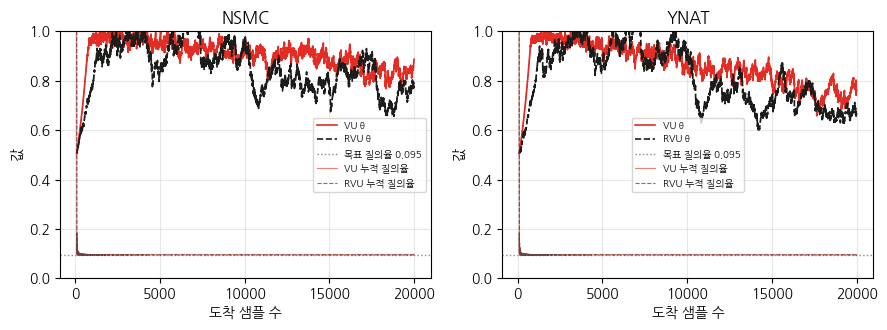

In [9]:
# ── θ 궤적 ────
traces = {}
for name, d in DATA.items():
    for label, delta in (("VU", 0.0), ("RVU", 1.0)):
        tr = []
        run_stream(make_vu(delta=delta, trace=tr), make_sim_oracle(d["y_pool"]), d, 0)
        traces[name, label] = np.array(tr)
        print(name, label, "θ 마지막 값", round(tr[-1][0], 4), "최종 질의율", round(tr[-1][1], 4))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, name in zip(axes, DATA):
    for (label, c, ls) in (("VU", ACCENT, "-"), ("RVU", INK, "--")):
        t = traces[name, label]
        ax.plot(N_INIT + np.arange(len(t)), t[:, 0], color=c, ls=ls, lw=1.2, label=f"{label} θ")
    ax.axhline(RATE, color=GRAY2, lw=1, ls=":", label=f"목표 질의율 {RATE:.3f}")
    for (label, c, ls) in (("VU", ACCENT, "-"), ("RVU", INK, "--")):
        t = traces[name, label]
        ax.plot(N_INIT + np.arange(len(t)), t[:, 1], color=c, ls=ls, lw=0.8, alpha=0.6, label=f"{label} 누적 질의율")
    ax.set(title=name.upper(), xlabel="도착 샘플 수", ylabel="값", ylim=(0, 1))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("out/ch06_theta_trace.png", dpi=200)

덩어리 크기(재학습 간격)가 결과를 얼마나 바꾸는지 VU로 잰다. 계산량 때문에 시드는 셋이다.

In [10]:
# ── 덩어리 크기 점검 ────
chunk_rows = []
for name, d in DATA.items():
    for c in (50, 200, 1000):
        r = run_stream_strategies({"VU": make_vu}, d, seeds=[0, 1, 2], chunk=c)
        chunk_rows.append(summarize_stream(r).assign(data=name, chunk=c))
chunk_tab = pd.concat(chunk_rows, ignore_index=True)[["data", "chunk", "ALC_label", "ALC_label_std", "ALC_seen", "final", "exhaust"]]
print(chunk_tab.to_string(index=False))

nsmc  VU 완료


nsmc  VU 완료


nsmc  VU 완료


ynat  VU 완료


ynat  VU 완료


ynat  VU 완료
data  chunk  ALC_label  ALC_label_std  ALC_seen  final  exhaust
nsmc     50     0.7421         0.0064    0.7424 0.7853  20000.0
nsmc    200     0.7385         0.0093    0.7390 0.7833  20000.0
nsmc   1000     0.7388         0.0084    0.7390 0.7845  20000.0
ynat     50     0.5940         0.0125    0.5939 0.6978  20000.0
ynat    200     0.5924         0.0120    0.5926 0.6914  20000.0
ynat   1000     0.5821         0.0075    0.5823 0.6863  20000.0


## 6.4 질의율과 성능의 절충

전략마다 예산을 다 쓴 도착 위치와 도착 축 ALC를 한 그림에 놓는다. 예산을 일찍 다 쓰면 이후 도착하는 샘플은 그냥 지나간다.

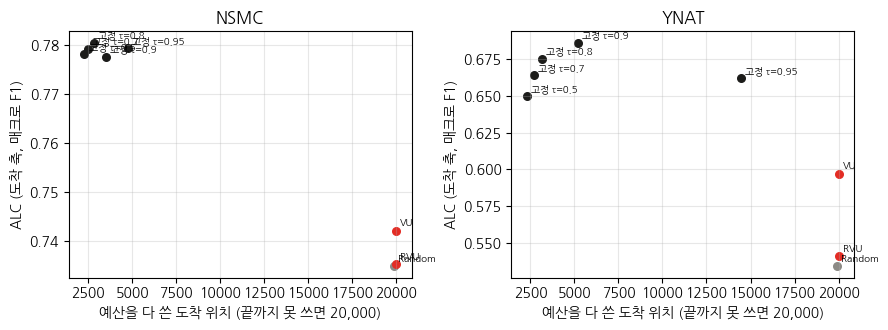

In [11]:
# ── 질의율 대 성능 그림 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, res.items()):
    t = summarize_stream(r)
    x = t.exhaust.fillna(20000)                     # 예산을 다 쓰지 못한 전략은 스트림 끝에 놓는다
    for (_, row), xi in zip(t.iterrows(), x):
        c = ACCENT if row.strategy in ("VU", "RVU") else (GRAY2 if row.strategy == "Random" else INK)
        ax.scatter(xi, row.ALC_seen, color=c, s=30)
        ax.annotate(row.strategy, (xi, row.ALC_seen), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set(title=name.upper(), xlabel="예산을 다 쓴 도착 위치 (끝까지 못 쓰면 20,000)", ylabel="ALC (도착 축, 매크로 F1)")
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("out/ch06_rate_vs_perf.png", dpi=200)

라벨 축과 도착 축의 학습 곡선을 Random, 가장 좋은 고정 임계값, VU, RVU로 그린다.

nsmc 도착 축 ALC가 가장 높은 고정 임계값: 고정 τ=0.8
ynat 도착 축 ALC가 가장 높은 고정 임계값: 고정 τ=0.9


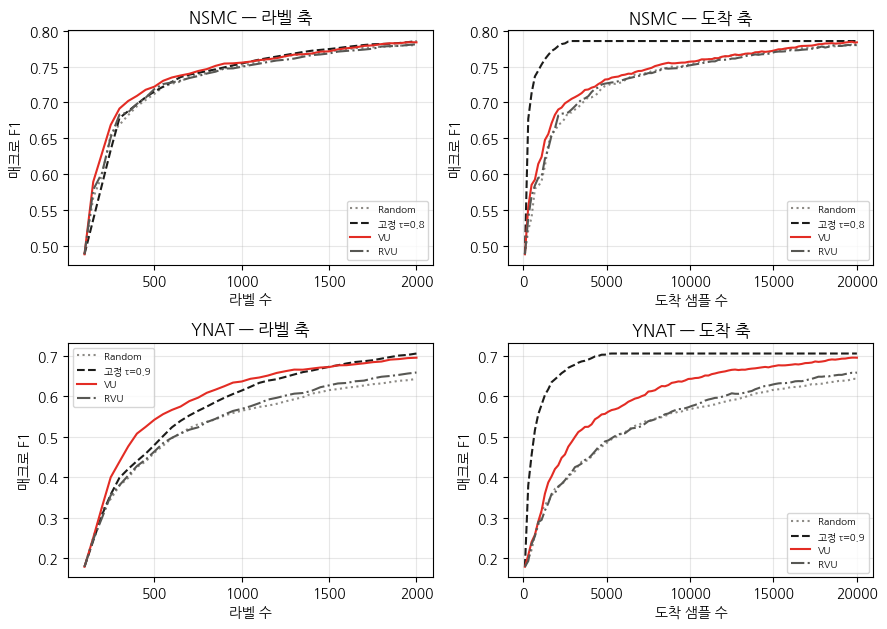

In [12]:
# ── 학습 곡선 ────
fig, axes = plt.subplots(2, 2, figsize=(9, 6.4))
for row, (name, r) in zip(axes, res.items()):
    t = summarize_stream(r)
    best = t[t.strategy.str.startswith("고정")].sort_values("ALC_seen").strategy.iloc[-1]
    print(name, "도착 축 ALC가 가장 높은 고정 임계값:", best)
    keep = ["Random", best, "VU", "RVU"]
    for strat, (c, ls) in zip(keep, [(GRAY2, ":"), (INK, "--"), (ACCENT, "-"), (GRAY, "-.")]):
        g = r[r.strategy == strat]
        lab = np.mean([label_curve(d) for _, d in g.groupby("seed")], axis=0)
        row[0].plot(GRID, lab, color=c, ls=ls, lw=1.5, label=strat)
        m = g.groupby("n_seen").f1.mean()
        row[1].plot(m.index, m.values, color=c, ls=ls, lw=1.5, label=strat)
    row[0].set(title=f"{name.upper()} — 라벨 축", xlabel="라벨 수", ylabel="매크로 F1")
    row[1].set(title=f"{name.upper()} — 도착 축", xlabel="도착 샘플 수", ylabel="매크로 F1")
    for ax in row:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("out/ch06_curves.png", dpi=200)

## 6.5 개념 표류 상황의 스트림 질의

YNAT 일곱 클래스를 A 묶음(정치·경제·사회)과 B 묶음(세계·스포츠·IT과학·생활문화)으로 나누고 도착 순서를 바꿔 클래스 사전 확률이 표류하게 만든다. 스트림 앞쪽 1/3은 A 묶음 비율 0.9, 가운데 1/3은 0.9에서 0.1로 선형으로 바뀌고, 뒤쪽 1/3은 0.1이다. 두 묶음에서 8,000개씩 뽑아 길이 16,000인 스트림을 만든다. 질의율 상한은 이 길이에 맞춰 다시 계산한다.

In [13]:
# ── 표류 스트림 구성 ────
YNAT_NAMES = ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]
GROUP_A = [YNAT_NAMES.index(c) for c in ("정치", "경제", "사회")]
DRIFT_LEN = 16000

def make_drift_order(y, seed, n_each=DRIFT_LEN // 2):
    rng = np.random.default_rng(seed)
    a = list(rng.permutation(np.flatnonzero(np.isin(y, GROUP_A)))[:n_each])
    b = list(rng.permutation(np.flatnonzero(~np.isin(y, GROUP_A)))[:n_each])
    t = np.arange(2 * n_each) / (2 * n_each)
    p_a = np.clip(0.9 - 0.8 * (t - 1 / 3) * 3, 0.1, 0.9)        # 0.9 → 0.1
    order = []
    for p in p_a:
        src = a if (rng.random() < p and a) or not b else b
        order.append(src.pop())
    return np.array(order)

yn = DATA["ynat"]
orders = {s: make_drift_order(yn["y_pool"], s) for s in SEEDS}
share = pd.Series(np.isin(yn["y_pool"][orders[0]], GROUP_A).astype(float)).rolling(1000).mean()
print("A 묶음 비율(1,000개 이동 평균) — 앞, 가운데, 끝:", share.iloc[999].round(3), share.iloc[DRIFT_LEN // 2].round(3), share.iloc[-1].round(3))

A 묶음 비율(1,000개 이동 평균) — 앞, 가운데, 끝: 0.89 0.602 0.05


고정 임계값 둘(0.8, 0.9), VU, RVU, Random을 같은 표류 스트림에서 비교한다. 지표는 고정 시험셋 매크로 F1과 사전 순차 매크로 F1이다. 사전 순차 지표는 도착 샘플을 학습 전에 예측한 결과를 1,000개 창으로 묶어 매크로 F1을 낸다. 정답은 평가에만 쓴다.

In [14]:
# ── 표류 실험 ────
DRIFT_RATE = (BUDGET - N_INIT) / (DRIFT_LEN - N_INIT)
DRIFT_F = {"Random": lambda: make_stream_random(DRIFT_RATE),
           "고정 τ=0.8": lambda: make_fixed(0.8), "고정 τ=0.9": lambda: make_fixed(0.9),
           "VU": lambda: make_vu(rate=DRIFT_RATE), "RVU": lambda: make_vu(rate=DRIFT_RATE, delta=1.0)}
oracle = make_sim_oracle(yn["y_pool"])
jobs = [(name, s) for name in DRIFT_F for s in SEEDS]
out = Parallel(n_jobs=-1)(delayed(run_stream)(DRIFT_F[name](), oracle, yn, s, order=orders[s]) for name, s in jobs)
drift = pd.concat([df.assign(strategy=name) for (name, _), (df, _, _) in zip(jobs, out)], ignore_index=True)
drift.to_csv("results/ch06_drift.csv", index=False)

W = 1000
preq_rows = []
for (name, s), (_, _, pred) in zip(jobs, out):
    truth = yn["y_pool"][orders[s][N_INIT:]]
    for i in range(0, len(pred) - W + 1, W):
        preq_rows.append(dict(strategy=name, seed=s, pos=N_INIT + i + W,
                              f1=f1_score(truth[i:i + W], pred[i:i + W], average="macro")))
preq = pd.DataFrame(preq_rows)
tab = summarize_stream(drift)
third = preq.assign(part=pd.cut(preq.pos, [0, DRIFT_LEN / 3, 2 * DRIFT_LEN / 3, DRIFT_LEN + 1], labels=["앞", "가운데", "뒤"]))
tab = tab.merge(third.groupby(["strategy", "part"], observed=True).f1.mean().unstack().round(4).add_prefix("사전순차_"),
                left_on="strategy", right_index=True)
print(tab[["strategy", "final", "labels", "exhaust", "사전순차_앞", "사전순차_가운데", "사전순차_뒤"]].to_string(index=False))

# 구간별 질의 수: 표류 뒤쪽에서도 라벨을 받았는가
asked = []
for (name, s), (_, idx_l, _) in zip(jobs, out):
    where = pd.Series(np.arange(len(orders[s])), index=orders[s]).loc[idx_l[N_INIT:]]   # 질의한 샘플의 도착 위치
    asked.append(dict(strategy=name, 앞=(where < DRIFT_LEN / 3).sum(), 가운데=((where >= DRIFT_LEN / 3) & (where < 2 * DRIFT_LEN / 3)).sum(),
                      뒤=(where >= 2 * DRIFT_LEN / 3).sum()))
print(pd.DataFrame(asked).groupby("strategy", sort=False).mean().round(1).to_string())

strategy  final  labels    exhaust  사전순차_앞  사전순차_가운데  사전순차_뒤
  Random 0.6592  2000.0 15720.0000  0.2918    0.3255  0.5036
고정 τ=0.8 0.4340  1240.0 10233.3333  0.2453    0.3551  0.4027
고정 τ=0.9 0.1252   100.0        NaN  0.2127    0.1616  0.0580
      VU 0.6956  2000.0 16000.0000  0.3095    0.4021  0.5556
     RVU 0.6702  2000.0 16000.0000  0.2949    0.3494  0.5020
              앞    가운데      뒤
strategy                     
Random    643.6  646.6  609.8
고정 τ=0.8  230.6  792.2  117.2
고정 τ=0.9    0.0    0.0    0.0
VU        626.0  637.0  637.0
RVU       625.8  637.2  637.0


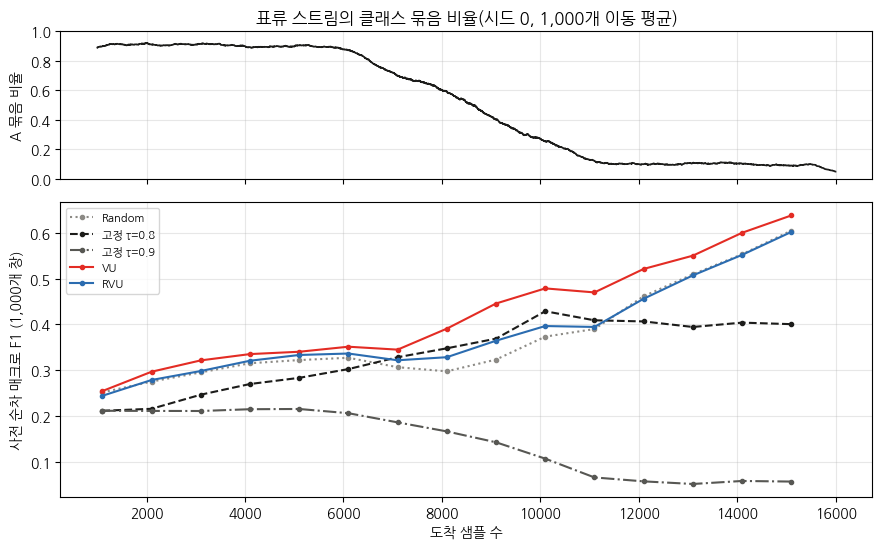

In [15]:
# ── 표류 그림 ────
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
axes[0].plot(np.arange(len(share)), share, color=INK, lw=1.2)
axes[0].set(ylabel="A 묶음 비율", ylim=(0, 1), title="표류 스트림의 클래스 묶음 비율(시드 0, 1,000개 이동 평균)")
axes[0].grid(alpha=0.3)
for (name, g), (c, ls) in zip(preq.groupby("strategy", sort=False), [(GRAY2, ":"), (INK, "--"), (GRAY, "-."), (ACCENT, "-"), ("#2B6CB0", "-")]):
    m = g.groupby("pos").f1.mean()
    axes[1].plot(m.index, m.values, color=c, ls=ls, lw=1.5, marker="o", ms=3, label=name)
axes[1].set(xlabel="도착 샘플 수", ylabel="사전 순차 매크로 F1 (1,000개 창)")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig("out/ch06_drift.png", dpi=200)

## 6.6 풀 기반 루프와의 비교

같은 라벨 수에서 3장의 풀 기반 엔트로피·Random과 스트림 전략을 라벨 축 ALC로 비교한다. 스트림 Random과 풀 Random이 비슷한지부터 확인한다.

In [16]:
# ── 풀 기반과의 비교 ────
for name, r in res.items():
    pool = pd.read_csv(f"results/ch03_{name}.csv")
    rows = [dict(scenario="풀", strategy=s, ALC_label=np.mean([alc(d.n_labeled.values, d.f1.values) for _, d in g.groupby("seed")]),
                 final=g.groupby("n_labeled").f1.mean().loc[BUDGET])
            for s, g in pool[pool.strategy.isin(["Random", "엔트로피"])].groupby("strategy")]
    t = summarize_stream(r)
    rows += [dict(scenario="스트림", strategy=row.strategy, ALC_label=row.ALC_label, final=row.final) for _, row in t.iterrows()]
    print(f"\n{name} 라벨 축 ALC (매크로 F1)")
    print(pd.DataFrame(rows).round(4).to_string(index=False))


nsmc 라벨 축 ALC (매크로 F1)
scenario  strategy  ALC_label  final
       풀    Random     0.7426 0.7802
       풀      엔트로피     0.7479 0.7860
     스트림    Random     0.7351 0.7801
     스트림  고정 τ=0.5     0.7336 0.7829
     스트림  고정 τ=0.7     0.7345 0.7842
     스트림  고정 τ=0.8     0.7365 0.7859
     스트림  고정 τ=0.9     0.7398 0.7833
     스트림 고정 τ=0.95     0.7431 0.7872
     스트림        VU     0.7416 0.7841
     스트림       RVU     0.7351 0.7814

ynat 라벨 축 ALC (매크로 F1)
scenario  strategy  ALC_label  final
       풀    Random     0.5335 0.6500
       풀      엔트로피     0.6164 0.7202
     스트림    Random     0.5343 0.6434
     스트림  고정 τ=0.5     0.5402 0.6619
     스트림  고정 τ=0.7     0.5492 0.6777
     스트림  고정 τ=0.8     0.5599 0.6905
     스트림  고정 τ=0.9     0.5772 0.7061
     스트림 고정 τ=0.95     0.5934 0.7184
     스트림        VU     0.5969 0.6958
     스트림       RVU     0.5412 0.6592
